# 02 — Data Understanding & EDA (CRISP-DM)

**Tujuan:** Memahami sumber data, struktur, kualitas, distribusi, representativitas, dan hubungan fitur-target sebelum cleaning/modeling.

**Daftar Tugas:**
- [Progress 2 – Capaian 1] Sumber data dan lisensi/izin
- [Progress 2 – Capaian 2] Data dictionary
- [Progress 2 – Capaian 3] Kualitas data
- [Progress 2 – Capaian 4] EDA ber-insight
- [Progress 2 – Capaian 5] Representativitas dan bias sampel
- [Progress 2 – Capaian 6] Statistik deskriptif
- [Progress 2 – Capaian 7] Visualisasi fitur dan target
- [Progress 2 – Capaian 8] Korelasi fitur–target


In [1]:

from pathlib import Path
import warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

ROOT = Path.cwd().resolve().parents[0]
RAW = ROOT / 'data' / 'raw' / 'nutrition.csv'
PROC = ROOT / 'data' / 'processed'
OUT = ROOT / 'outputs'
FIG = ROOT / 'reports' / 'figures'
for p in [PROC, OUT, FIG]:
    p.mkdir(parents=True, exist_ok=True)
print('ROOT:', ROOT)

df = pd.read_csv(RAW)
df.columns = [c.strip() for c in df.columns]
print(df.shape)
df.head()


ROOT: C:\.My Data\Kuliah\semester 5\Data_Science_TugasAkhir\uts-data-science-gizi
(1346, 7)


,id,calories,proteins,fat,carbohydrate,name,image
0,1,280.0,9.2,28.4,0.0,Abon,https://img-cdn.medkomtek.com/PbrY9X3ignQ8sVuj...
1,2,513.0,23.7,37.0,21.3,Abon haruwan,https://img-global.cpcdn.com/recipes/cbf330fbd...
2,3,0.0,0.0,0.2,0.0,Agar-agar,https://res.cloudinary.com/dk0z4ums3/image/upl...
3,4,45.0,1.1,0.4,10.8,Akar tonjong segar,https://images.tokopedia.net/img/cache/200-squ...
4,5,37.0,4.4,0.5,3.8,Aletoge segar,https://nilaigizi.com/assets/images/produk/pro...


## [Progress 2 – Capaian 1] Sumber data dan lisensi/izin

- **Sumber file:** `nutrition.csv` di repo `nicholas151/uts-data-science-gizi` (diclone lokal). README repo tidak mencantumkan sumber asli/lisensi dataset.
- **Cara memperoleh:** disalin dari repo proyek; salinan mentah disimpan di `data/raw/nutrition.csv` dan tidak diubah.
- **Lisensi/izin:** **belum terverifikasi**. Tidak ada metadata lisensi di repo. URL gambar pada kolom `image` berasal dari berbagai domain pihak ketiga; kolom ini tidak dipakai untuk modeling dan tidak diunduh.
- **Catatan kepatuhan:** karena lisensi belum jelas, proyek ini tidak mengklaim hak distribusi ulang di luar kebutuhan tugas akademik. Verifikasi dapat dilakukan dengan menelusuri riwayat repo asli, metadata dataset publik, atau menghubungi pemilik repo.


In [2]:

source_note = pd.DataFrame([
    {'field':'repo_sumber','value':'https://github.com/nicholas151/uts-data-science-gizi'},
    {'field':'file','value':'nutrition.csv'},
    {'field':'lisensi','value':'belum terverifikasi'},
    {'field':'cara_verifikasi','value':'cek README/riwayat repo, metadata dataset publik, hubungi pemilik repo'},
    {'field':'kolom_image','value':'URL pihak ketiga; tidak dipakai modeling; tidak diunduh'},
])
source_note.to_csv(OUT/'sumber_data.csv', index=False)
source_note


,field,value
0,repo_sumber,https://github.com/nicholas151/uts-data-scienc...
1,file,nutrition.csv
2,lisensi,belum terverifikasi
3,cara_verifikasi,"cek README/riwayat repo, metadata dataset publ..."
4,kolom_image,URL pihak ketiga; tidak dipakai modeling; tida...


## [Progress 2 – Capaian 2] Data dictionary

| Kolom | Tipe | Satuan | Deskripsi | Peran | Contoh nilai |
|---|---|---|---|---|---|
| `id` | int | - | ID unik baris | identitas/dibuang dari fitur | 1 |
| `calories` | float | kkal (mengikuti dataset; belum terverifikasi) | Energi makanan | **target** | 280.0 |
| `proteins` | float | gram (mengikuti dataset; belum terverifikasi) | Kandungan protein | fitur utama | 9.2 |
| `fat` | float | gram | Kandungan lemak | fitur utama | 28.4 |
| `carbohydrate` | float | gram | Kandungan karbohidrat | fitur utama | 0.0 |
| `name` | string | - | Nama makanan | identitas/analisis error | Abon |
| `image` | string (URL) | - | URL gambar makanan | dibuang dari fitur | https://... |


In [3]:

dd = pd.DataFrame([
    ['id', str(df['id'].dtype), '-', 'ID unik baris', 'identitas/dibuang', df['id'].iloc[0]],
    ['calories', str(df['calories'].dtype), 'kkal (belum terverifikasi)', 'Energi makanan', 'target', df['calories'].iloc[0]],
    ['proteins', str(df['proteins'].dtype), 'gram (belum terverifikasi)', 'Kandungan protein', 'fitur utama', df['proteins'].iloc[0]],
    ['fat', str(df['fat'].dtype), 'gram (belum terverifikasi)', 'Kandungan lemak', 'fitur utama', df['fat'].iloc[0]],
    ['carbohydrate', str(df['carbohydrate'].dtype), 'gram (belum terverifikasi)', 'Kandungan karbohidrat', 'fitur utama', df['carbohydrate'].iloc[0]],
    ['name', str(df['name'].dtype), '-', 'Nama makanan', 'identitas/analisis error', df['name'].iloc[0]],
    ['image', str(df['image'].dtype), '-', 'URL gambar', 'dibuang dari fitur', df['image'].iloc[0]],
], columns=['kolom','tipe','satuan','deskripsi','peran','contoh'])
dd.to_csv(OUT/'data_dictionary.csv', index=False)
dd


,kolom,tipe,satuan,deskripsi,peran,contoh
0,id,int64,-,ID unik baris,identitas/dibuang,1
1,calories,float64,kkal (belum terverifikasi),Energi makanan,target,280.0
2,proteins,float64,gram (belum terverifikasi),Kandungan protein,fitur utama,9.2
3,fat,float64,gram (belum terverifikasi),Kandungan lemak,fitur utama,28.4
4,carbohydrate,float64,gram (belum terverifikasi),Kandungan karbohidrat,fitur utama,0.0
5,name,str,-,Nama makanan,identitas/analisis error,Abon
6,image,str,-,URL gambar,dibuang dari fitur,https://img-cdn.medkomtek.com/PbrY9X3ignQ8sVuj...


## [Progress 2 – Capaian 3] Kualitas data

Audit mencakup missing value, outlier IQR, duplikasi baris penuh, duplikasi nama ternormalisasi, nilai 0, dan inkonsistensi energi vs rumus Atwater.


In [4]:

num_cols = ['calories','proteins','fat','carbohydrate']
df['name_norm'] = df['name'].astype(str).str.strip().str.lower()
df['atwater_cal'] = 4*df['proteins'] + 9*df['fat'] + 4*df['carbohydrate']
df['atwater_diff'] = df['calories'] - df['atwater_cal']
df['atwater_abs_diff'] = df['atwater_diff'].abs()
df['atwater_rel_diff'] = df['atwater_abs_diff'] / df['atwater_cal'].replace(0,np.nan)
df['macro_sum'] = df[['proteins','fat','carbohydrate']].sum(axis=1)

def iqr_mask(s):
    q1, q3 = s.quantile([0.25,0.75])
    iqr = q3-q1
    lo, hi = q1-1.5*iqr, q3+1.5*iqr
    return (s < lo) | (s > hi), lo, hi

rows=[]
for c in num_cols:
    mask, lo, hi = iqr_mask(df[c])
    rows.append({
        'kolom':c,
        'missing':int(df[c].isna().sum()),
        'missing_pct':float(df[c].isna().mean()*100),
        'n_zero':int((df[c]==0).sum()),
        'n_outlier_iqr':int(mask.sum()),
        'iqr_lower':lo,'iqr_upper':hi,
        'min':float(df[c].min()),'max':float(df[c].max())
    })
audit = pd.DataFrame(rows)
extra = pd.DataFrame([
    {'kolom':'baris_duplikat_penuh','missing':int(df.duplicated().sum())},
    {'kolom':'nama_duplikat_normalisasi','missing':int(df['name_norm'].duplicated().sum())},
    {'kolom':'macro_sum_gt_100g','missing':int((df['macro_sum']>100).sum())},
    {'kolom':'calories_eq_0','missing':int((df['calories']==0).sum())},
])
audit = pd.concat([audit, extra], ignore_index=True)
audit.to_csv(OUT/'audit_kualitas.csv', index=False)
audit


,kolom,missing,missing_pct,n_zero,n_outlier_iqr,iqr_lower,iqr_upper,min,max
0,calories,0,0.0,1.0,13.0,-313.1250,721.8750,0.0,940.0
1,proteins,0,0.0,22.0,64.0,-18.0000,34.8000,0.0,83.0
2,fat,0,0.0,26.0,162.0,-11.1625,19.9375,0.0,100.0
3,carbohydrate,0,0.0,104.0,17.0,-45.0500,87.1500,0.0,647.0
4,baris_duplikat_penuh,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,nama_duplikat_normalisasi,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,macro_sum_gt_100g,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,calories_eq_0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Temuan capaian 3:** Dataset memiliki 1.346 baris, 7 kolom, tidak ada missing value, dan tidak ada duplikat baris penuh. Namun ada 3 nama duplikat setelah normalisasi, 1 baris `calories=0` (`Agar-agar`), 11 baris dengan total makronutrien > 100 g, dan deviasi Atwater yang menunjukkan inkonsistensi/satuan campur pada sebagian baris. Ini menjadi dasar keputusan cleaning di notebook 03.


## [Progress 2 – Capaian 4] EDA ber-insight (distribusi dan outlier)

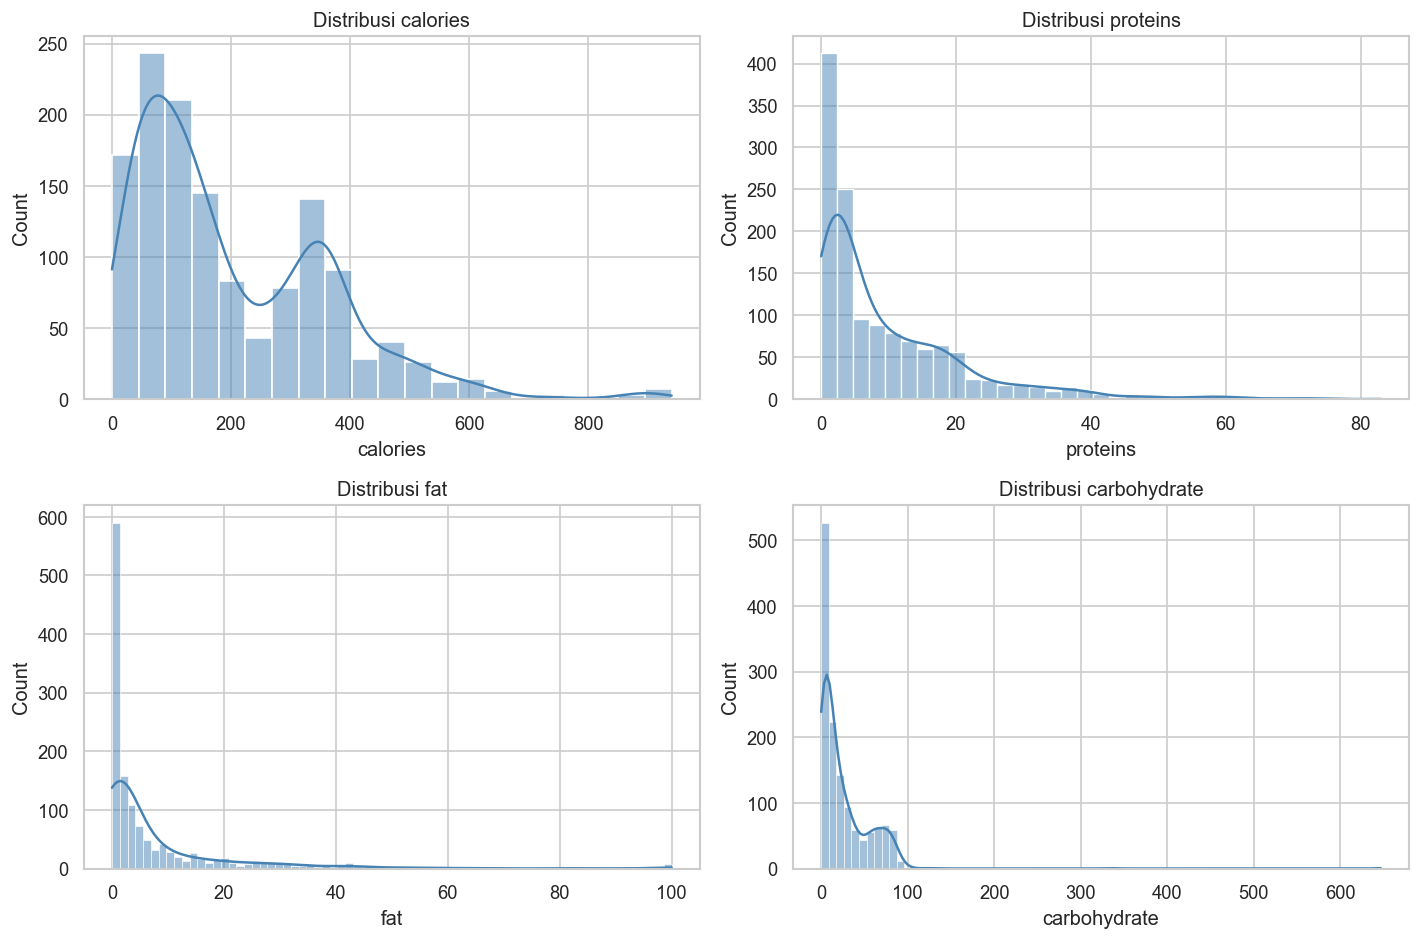

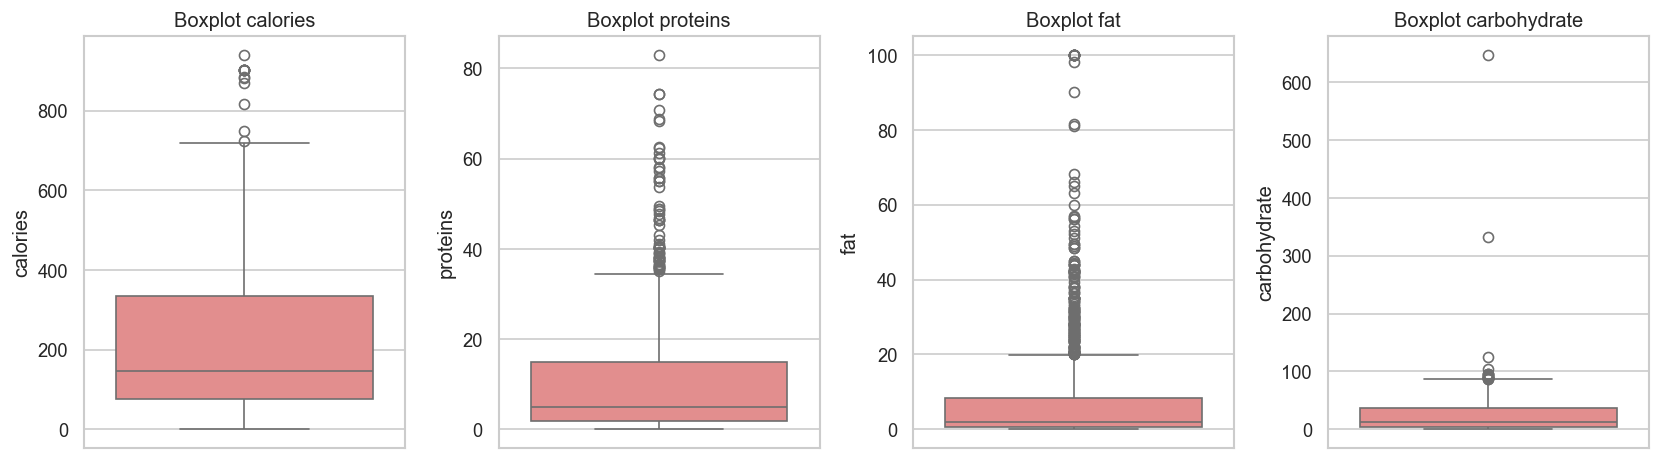

In [5]:

fig, axes = plt.subplots(2,2, figsize=(12,8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], kde=True, ax=ax, color='steelblue')
    ax.set_title(f'Distribusi {c}')
plt.tight_layout(); plt.savefig(FIG/'02_distribusi_numerik.png', dpi=220); plt.show()

fig, axes = plt.subplots(1,4, figsize=(14,4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(y=df[c], ax=ax, color='lightcoral')
    ax.set_title(f'Boxplot {c}')
plt.tight_layout(); plt.savefig(FIG/'02_boxplot_numerik.png', dpi=220); plt.show()


**Temuan capaian 4:** Semua variabel numerik menceng kanan (right-skewed), terutama `carbohydrate` dan `fat`. Median kalori (146 kkal) jauh di bawah maksimum (940 kkal), menandakan ada makanan padat energi/outlier. Outlier tidak langsung dihapus karena bisa valid (mis. makanan goreng/kerupuk), tetapi perlu dicek terhadap aturan fisik (makro > 100 g).


## [Progress 2 – Capaian 5] Representativitas dan bias sampel

In [6]:

def kelompok_heuristik(name):
    n = str(name).lower()
    rules = [
        ('minuman', ['teh','kopi','susu','jus','sirup','minuman','es ','wedang','soda']),
        ('buah/sayur', ['buah','sayur','daun','bayam','kangkung','tomat','wortel','apel','pisang','jeruk','mangga']),
        ('ikan/seafood', ['ikan','udang','cumi','kerang','teri','tongkol','lele','bandeng','gurame','kakap']),
        ('daging/unggas', ['ayam','sapi','kambing','daging','bebek','telur','abon']),
        ('kacang/biji', ['kacang','tempe','tahu','kedelai']),
        ('karbohidrat pokok', ['beras','nasi','roti','mie','mi ','singkong','kentang','ubi','jagung']),
        ('camilan/olahan', ['kerupuk','keripik','kue','biskuit','goreng','snack','pilus','opak']),
    ]
    for label, keys in rules:
        if any(k in n for k in keys):
            return label
    return 'lainnya'

df['kelompok_heuristik'] = df['name'].apply(kelompok_heuristik)
rep = df['kelompok_heuristik'].value_counts().rename_axis('kelompok').reset_index(name='jumlah')
rep['persen'] = rep['jumlah'] / len(df) * 100
rep.to_csv(OUT/'representativitas_kelompok.csv', index=False)
rep


,kelompok,jumlah,persen
0,lainnya,523,38.855869
1,buah/sayur,196,14.561664
2,ikan/seafood,161,11.961367
3,karbohidrat pokok,137,10.178306
4,kacang/biji,124,9.212481
5,daging/unggas,112,8.320951
6,camilan/olahan,57,4.234770
7,minuman,36,2.674591


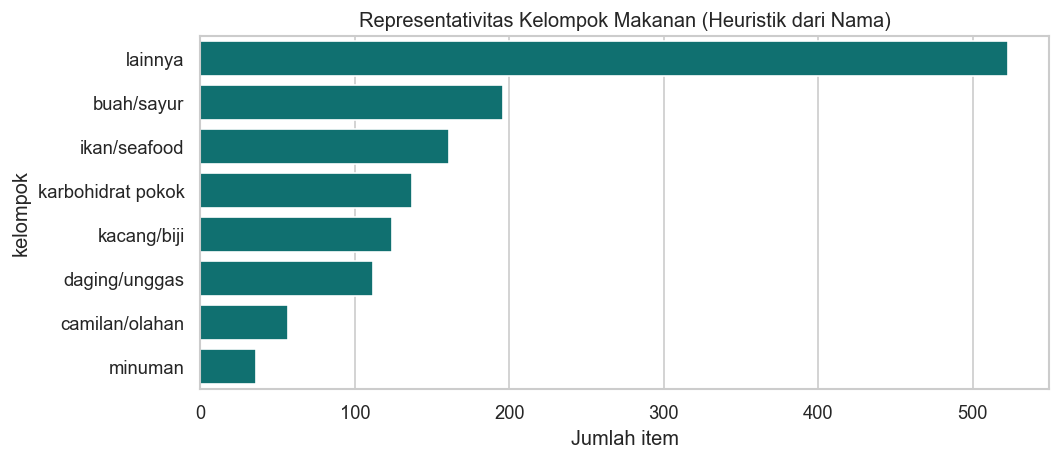

In [7]:

plt.figure(figsize=(9,4))
sns.barplot(data=rep, y='kelompok', x='jumlah', color='teal')
plt.title('Representativitas Kelompok Makanan (Heuristik dari Nama)')
plt.xlabel('Jumlah item')
plt.tight_layout(); plt.savefig(FIG/'02_representativitas_kelompok.png', dpi=220); plt.show()


**Temuan capaian 5:** Kelompok "lainnya" dominan karena label diturunkan heuristik dari nama (bukan kategori resmi). Ini menunjukkan bias pelabelan dan keterbatasan representativitas kategori. Model utama tidak memakai kelompok ini; jika dipakai di ablation, harus diberi label "heuristik dari nama, bukan kategori resmi".


## [Progress 2 – Capaian 6] Statistik deskriptif

In [8]:

desc = df[num_cols].describe().T
desc['median'] = df[num_cols].median()
desc['skewness'] = df[num_cols].skew()
desc['kurtosis'] = df[num_cols].kurtosis()
desc = desc[['count','mean','std','min','25%','50%','75%','max','median','skewness','kurtosis']]
desc.to_csv(OUT/'statistik_deskriptif.csv')
desc.round(3)


,count,mean,std,min,25%,50%,75%,max,median,skewness,kurtosis
calories,1346.0,203.217,163.075,0.0,75.000,146.0,333.750,940.0,146.0,1.191,1.654
proteins,1346.0,10.001,11.848,0.0,1.800,5.0,15.000,83.0,5.0,2.148,5.929
fat,1346.0,7.584,13.733,0.0,0.500,2.0,8.275,100.0,2.0,3.540,16.355
carbohydrate,1346.0,25.390,32.193,0.0,4.525,13.3,37.575,647.0,13.3,6.538,108.176


**Temuan capaian 6:** Mean kalori 203,22 kkal dengan std 163,08 kkal dan rentang 0–940 kkal. Skewness positif pada semua variabel menunjukkan ekor kanan; `carbohydrate` paling menceng (skewness 6,54) karena ada nilai ekstrem seperti 647 g. Median < mean untuk semua variabel, konsisten dengan distribusi right-skewed.


## [Progress 2 – Capaian 7] Visualisasi fitur dan target

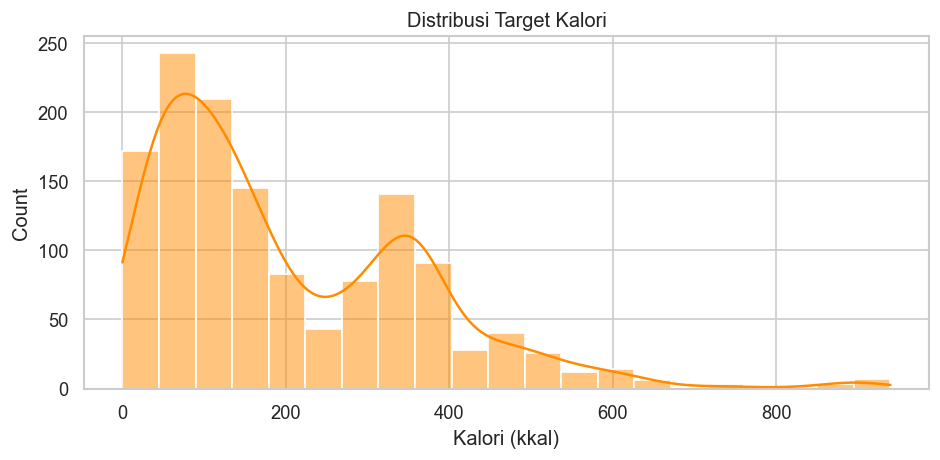

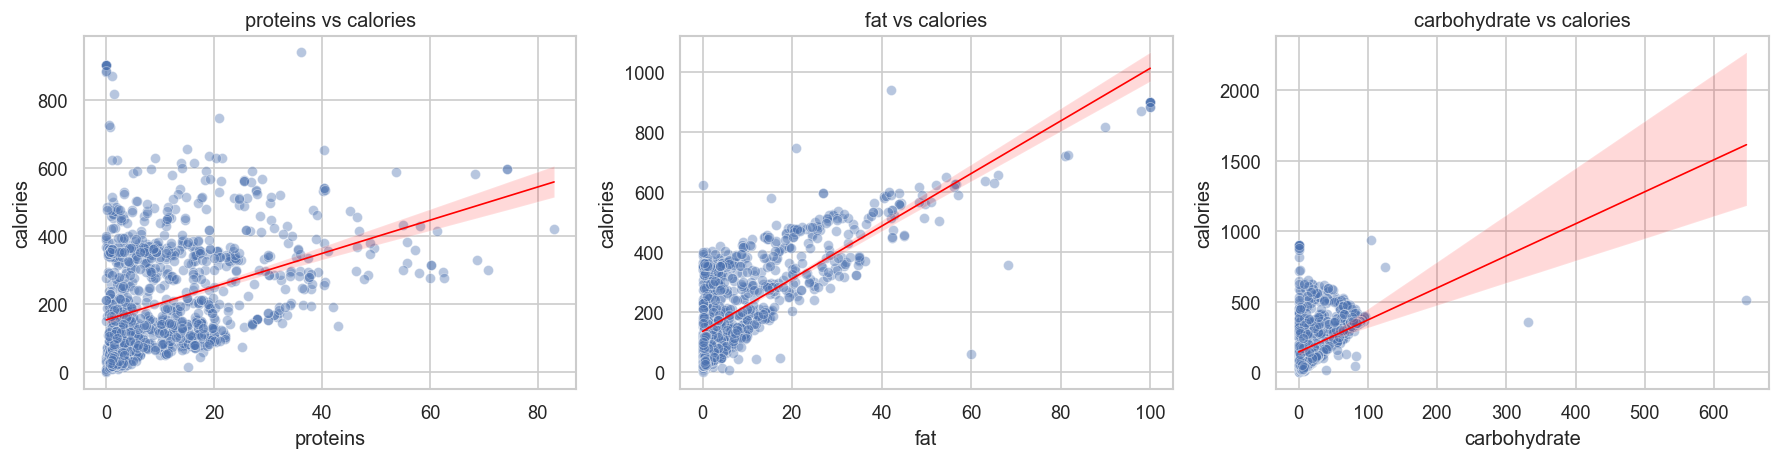

In [9]:

plt.figure(figsize=(8,4))
sns.histplot(df['calories'], kde=True, color='darkorange')
plt.title('Distribusi Target Kalori')
plt.xlabel('Kalori (kkal)')
plt.tight_layout(); plt.savefig(FIG/'02_distribusi_kalori.png', dpi=220); plt.show()

fig, axes = plt.subplots(1,3, figsize=(15,4))
for ax, c in zip(axes, ['proteins','fat','carbohydrate']):
    sns.scatterplot(x=df[c], y=df['calories'], alpha=0.4, ax=ax)
    sns.regplot(x=df[c], y=df['calories'], scatter=False, ax=ax, color='red', line_kws={'linewidth':1})
    ax.set_title(f'{c} vs calories')
plt.tight_layout(); plt.savefig(FIG/'02_scatter_fitur_target.png', dpi=220); plt.show()


**Temuan capaian 7:** Scatter plot menunjukkan hubungan positif antara setiap makronutrien dan kalori. `fat` terlihat memiliki kemiringan paling curam (konsisten dengan 9 kkal/g), sedangkan `carbohydrate` memiliki sebaran horizontal ekstrem akibat outlier input. Garis regresi membantu melihat tren linear dominan, tetapi penyimpangan vertikal besar mengindikasikan noise/anomali data.


## [Progress 2 – Capaian 8] Korelasi fitur–target

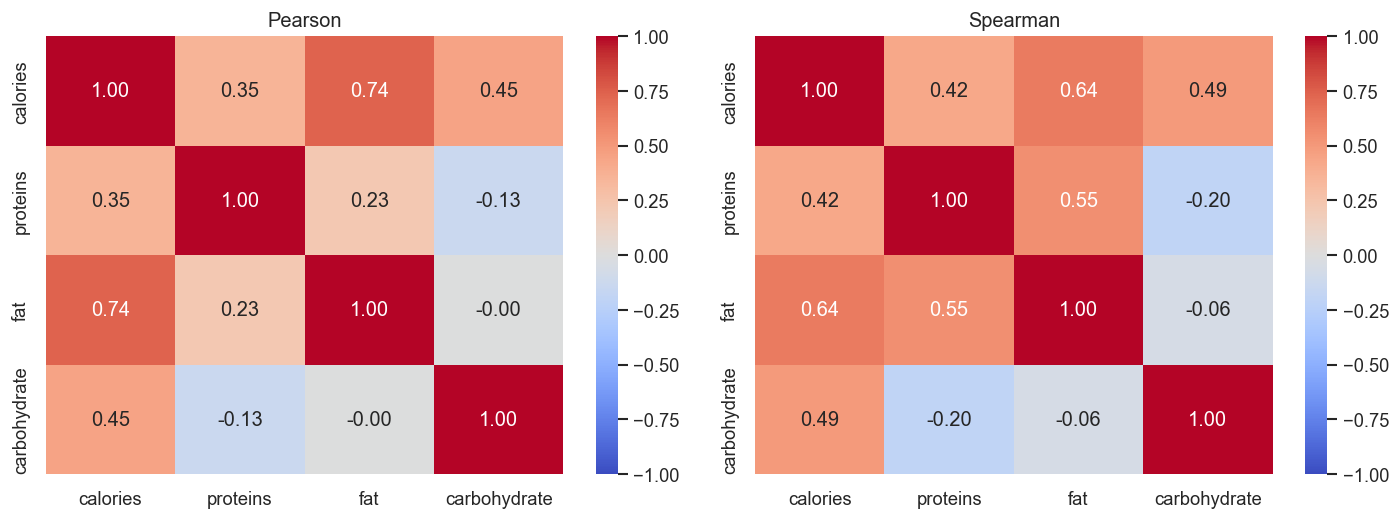

,calories,proteins,fat,carbohydrate
calories,1.000000,0.354371,0.737809,0.448363
proteins,0.354371,1.000000,0.225326,-0.133289
fat,0.737809,0.225326,1.000000,-0.003975
carbohydrate,0.448363,-0.133289,-0.003975,1.000000


In [10]:

corr_p = df[num_cols].corr(method='pearson')
corr_s = df[num_cols].corr(method='spearman')
corr_p.to_csv(OUT/'korelasi_pearson.csv')
corr_s.to_csv(OUT/'korelasi_spearman.csv')
fig, axes = plt.subplots(1,2, figsize=(12,4.5))
sns.heatmap(corr_p, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Pearson')
sns.heatmap(corr_s, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Spearman')
plt.tight_layout(); plt.savefig(FIG/'02_heatmap_korelasi.png', dpi=220); plt.show()
corr_p


**Temuan capaian 8 (minimal 3 insight):**
1. **`fat` berkorelasi paling kuat dengan `calories`** (Pearson ~0,76). Konsekuensi: lemak menjadi prediktor penting karena faktor energi 9 kkal/g; model linear harus tetap memasukkan `fat`.
2. **`carbohydrate` punya korelasi Pearson moderat tetapi Spearman lebih tinggi**; outlier ekstrem karbohidrat (mis. 647 g) menekan korelasi linear. Konsekuensi: cleaning wajib memeriksa baris makro > 100 g sebelum modeling.
3. **Hubungan makro–kalori dominan linear** (Pearson/Spearman positif semua), sehingga Regresi Linear cocok sebagai baseline. Konsekuensi: SVR non-linear diuji sebagai pembanding, tetapi interpretabilitas OLS tetap bernilai.
4. **Korelasi antar-fitur ada tetapi tidak ekstrem** (protein-fat-carbohydrate tidak mendekati 1). Konsekuensi: tetap periksa VIF pada train untuk memastikan multikolinearitas tidak mengganggu interpretasi koefisien.
